<a href="https://colab.research.google.com/github/joannapeniket/optiver-volatility/blob/main/optiver_volatility.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Short-horizon realised volatility from order-book data

**Data:** Optiver Realized Volatility Prediction (Kaggle, 2021). For each of 112 stocks and ~3,800 ten-minute windows (`time_id`), we see the first 10 minutes of level-1/level-2 order book and trades, and must predict the realised volatility of the **next** 10 minutes.

**Plan**
1. Build a small, interpretable set of order-book features per (stock, time window).
2. Split train/validation/test **by `time_id`**, so no time window appears in more than one set.
3. Compare three models of increasing complexity:
   - **Naive persistence** — next-10-min vol = last-10-min vol
   - **Linear regression on logs** — a few vol features, fit in log space
   - **LightGBM** — all features, trained to directly minimise the competition metric
4. Evaluate on the held-out test set once, with RMSPE (the competition metric).

**Metric.** Root mean squared *percentage* error:
$$\text{RMSPE} = \sqrt{\tfrac{1}{n}\textstyle\sum_i \left(\tfrac{y_i - \hat y_i}{y_i}\right)^2}$$
Because errors are relative, a miss on a calm stock counts as much as a miss on a volatile one.

## 0. Setup

Run this in **Google Colab** (CPU runtime is fine — no GPU needed).

Before the download cell works you need to:
1. Go to the competition page on Kaggle (`kaggle.com/competitions/optiver-realized-volatility-prediction`) → **Data** tab → accept the rules (one click; the competition is closed but the data stays downloadable).
2. Kaggle → Settings → **API → Create New Token**. This downloads `kaggle.json`.
3. Run the next cell and upload `kaggle.json` when prompted.

In [ ]:
# --- Config -------------------------------------------------------------
DATA_DIR = "optiver_data"   # where the competition files end up
N_STOCKS = None             # None = all 112 stocks; set e.g. 20 for a quick first run
SEED = 42
DOWNLOAD = False

In [ ]:
import os
from google.colab import drive
drive.mount("/content/drive")

SRC = "/content/drive/MyDrive/optiver"
if not os.path.exists(f"{DATA_DIR}/train.csv"):
    os.makedirs(DATA_DIR, exist_ok=True)
    !cp -r "{SRC}/train.csv" "{SRC}/book_train.parquet" "{SRC}/trade_train.parquet" {DATA_DIR}/
print(os.listdir(DATA_DIR))
print(len(os.listdir(f"{DATA_DIR}/book_train.parquet")), "stocks")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
['book_train.parquet', 'trade_train.parquet', 'train.csv']
112 stocks


In [ ]:
!pip -q install lightgbm
import glob, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb
from joblib import Parallel, delayed
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import GroupShuffleSplit

np.random.seed(SEED)
pd.set_option("display.float_format", lambda x: f"{x:.4f}")

def rmspe(y, p):
    y, p = np.asarray(y), np.asarray(p)
    return float(np.sqrt(np.mean(((y - p) / y) ** 2)))

## 1. Look at the raw data

Three inputs:
- `train.csv` — one row per (stock_id, time_id) with the **target**: realised vol over the next 10 minutes.
- `book_train.parquet/stock_id=k/` — order-book snapshots for the first 10 minutes (`seconds_in_bucket` 0–599): best two bid/ask prices and sizes. A row appears only when the book changes.
- `trade_train.parquet/stock_id=k/` — executed trades in the same window (price, size, order count).

Prices are normalised to 1 at the start of each window, so only *relative* moves matter.

In [ ]:
train = pd.read_csv(f"{DATA_DIR}/train.csv")
stock_ids = sorted(train.stock_id.unique())
if N_STOCKS:
    stock_ids = stock_ids[:N_STOCKS]
    train = train[train.stock_id.isin(stock_ids)].reset_index(drop=True)
print(f"{len(train):,} rows | {train.stock_id.nunique()} stocks | {train.time_id.nunique()} time windows")

book0 = pd.read_parquet(f"{DATA_DIR}/book_train.parquet/stock_id={stock_ids[0]}")
trade0 = pd.read_parquet(f"{DATA_DIR}/trade_train.parquet/stock_id={stock_ids[0]}")
display(book0.head())
display(trade0.head())
train.target.describe()

428,932 rows | 112 stocks | 3830 time windows


,time_id,seconds_in_bucket,bid_price1,ask_price1,bid_price2,ask_price2,bid_size1,ask_size1,bid_size2,ask_size2
0,5,0,1.0014,1.0023,1.0014,1.0024,3,226,2,100
1,5,1,1.0014,1.0023,1.0014,1.0024,3,100,2,100
2,5,5,1.0014,1.0023,1.0014,1.0024,3,100,2,100
3,5,6,1.0014,1.0023,1.0014,1.0024,3,126,2,100
4,5,7,1.0014,1.0023,1.0014,1.0024,3,126,2,100


,time_id,seconds_in_bucket,price,size,order_count
0,5,21,1.0023,326,12
1,5,46,1.0028,128,4
2,5,50,1.0028,55,1
3,5,57,1.0032,121,5
4,5,68,1.0036,4,1


,target
count,428932.0000
mean,0.0039
std,0.0029
min,0.0001
25%,0.0020
50%,0.0030
75%,0.0047
max,0.0703


**Weighted average price (WAP).** The mid-price ignores how much size sits at each side. WAP leans towards the side with *less* size — if the ask is thin, the next trade is more likely to lift it, so the "fair" price sits closer to the ask:

$$\text{WAP} = \frac{P_\text{bid}\,S_\text{ask} + P_\text{ask}\,S_\text{bid}}{S_\text{bid} + S_\text{ask}}$$

**Realised volatility** over a window is the root sum of squared log returns of WAP: $\sigma = \sqrt{\sum_t r_t^2}$, with $r_t = \log(\text{WAP}_t / \text{WAP}_{t-1})$. The target is exactly this, computed over the *next* 10 minutes.

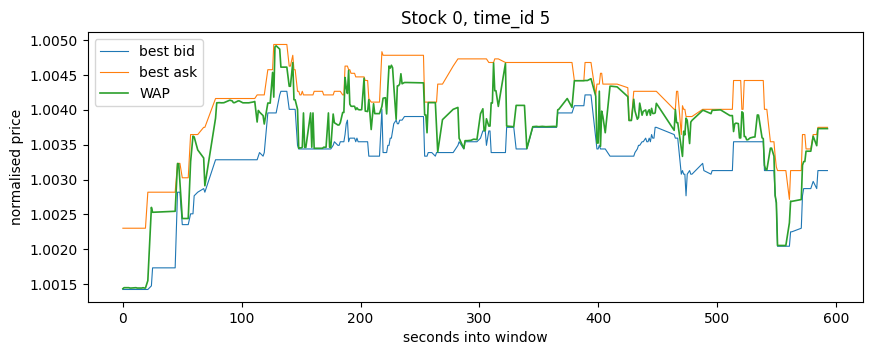

In [ ]:
def add_wap(book):
    b = book
    b["wap1"] = (b.bid_price1 * b.ask_size1 + b.ask_price1 * b.bid_size1) / (b.bid_size1 + b.ask_size1)
    b["wap2"] = (b.bid_price2 * b.ask_size2 + b.ask_price2 * b.bid_size2) / (b.bid_size2 + b.ask_size2)
    return b

book0 = add_wap(book0)
tid = book0.time_id.iloc[0]
w = book0[book0.time_id == tid]
fig, ax = plt.subplots(figsize=(10, 3.5))
ax.plot(w.seconds_in_bucket, w.bid_price1, lw=0.8, label="best bid")
ax.plot(w.seconds_in_bucket, w.ask_price1, lw=0.8, label="best ask")
ax.plot(w.seconds_in_bucket, w.wap1, lw=1.2, label="WAP")
ax.set(xlabel="seconds into window", ylabel="normalised price", title=f"Stock {stock_ids[0]}, time_id {tid}")
ax.legend(); plt.show()

## 2. Features

One row per (stock, time window). Everything is computed from the first 10 minutes only — nothing from the target window.

| Group | Features | Intuition |
|---|---|---|
| Realised vol | RV of WAP1 and WAP2 over the full window, last 300s, last 150s | Vol clusters: recent vol is the best single predictor. The sub-windows let the model weight the most recent activity. |
| Spread | mean relative bid-ask spread | Wide spreads ↔ uncertainty / thin liquidity |
| Depth | mean total size at top 2 levels; mean size imbalance | Thin books move more for the same flow |
| Activity | number of book updates | Busy books ↔ more information arriving |
| Trades | number of trades, total size, RV of trade prices | Actual executions, not just quotes |
| Market-wide | mean of each stock's RV across all stocks in the same `time_id` | Vol is partly a market regime. Legitimate: all stocks' first 10 minutes are observed together before the prediction is made. |

In [ ]:
def rv(r):
    return np.sqrt(np.sum(r ** 2))

def book_features(stock_id):
    b = pd.read_parquet(f"{DATA_DIR}/book_train.parquet/stock_id={stock_id}")
    b = add_wap(b)
    g = b.groupby("time_id")
    b["r1"] = np.log(b.wap1).groupby(b.time_id).diff()
    b["r2"] = np.log(b.wap2).groupby(b.time_id).diff()
    b["spread"] = (b.ask_price1 - b.bid_price1) / ((b.ask_price1 + b.bid_price1) / 2)
    b["depth"] = b.bid_size1 + b.ask_size1 + b.bid_size2 + b.ask_size2
    b["imbalance"] = (b.bid_size1 + b.bid_size2 - b.ask_size1 - b.ask_size2).abs() / b.depth
    b["r1_sq"], b["r2_sq"] = b.r1 ** 2, b.r2 ** 2

    out = b.groupby("time_id").agg(
        rv1=("r1_sq", "sum"), rv2=("r2_sq", "sum"),
        spread=("spread", "mean"), depth=("depth", "mean"),
        imbalance=("imbalance", "mean"), n_updates=("r1", "size"),
    )
    for s in (300, 450):  # last 300s and last 150s
        late = b[b.seconds_in_bucket >= s].groupby("time_id")
        out[f"rv1_last{600-s}"] = late.r1_sq.sum()
        out[f"rv2_last{600-s}"] = late.r2_sq.sum()
    rv_cols = [c for c in out if c.startswith("rv")]
    out[rv_cols] = np.sqrt(out[rv_cols])   # sum of squares -> realised vol
    return out.reset_index().assign(stock_id=stock_id)

def trade_features(stock_id):
    t = pd.read_parquet(f"{DATA_DIR}/trade_train.parquet/stock_id={stock_id}")
    t["r_sq"] = np.log(t.price).groupby(t.time_id).diff() ** 2
    out = t.groupby("time_id").agg(
        trade_rv=("r_sq", "sum"), n_trades=("price", "size"),
        trade_size=("size", "sum"), trade_orders=("order_count", "sum"),
    )
    out["trade_rv"] = np.sqrt(out.trade_rv)
    return out.reset_index().assign(stock_id=stock_id)

def features_for_stock(stock_id):
    return book_features(stock_id).merge(trade_features(stock_id), on=["stock_id", "time_id"], how="left")

t0 = time.time()
feat = pd.concat(Parallel(n_jobs=-1)(delayed(features_for_stock)(s) for s in stock_ids), ignore_index=True)
print(f"Features for {len(stock_ids)} stocks in {time.time()-t0:.0f}s")

df = train.merge(feat, on=["stock_id", "time_id"], how="left")
trade_cols = ["trade_rv", "n_trades", "trade_size", "trade_orders"]
df[trade_cols] = df[trade_cols].fillna(0)        # no trades in the window -> zero activity
df = df.fillna(df.median(numeric_only=True))      # rare windows with too few book updates

# Market-wide vol regime: average across stocks within each time window
for c in ["rv1", "rv1_last300", "rv1_last150", "spread"]:
    df[f"mkt_{c}"] = df.groupby("time_id")[c].transform("mean")

print(df.shape); df.head()

Features for 112 stocks in 79s
(428932, 21)


,stock_id,time_id,target,rv1,rv2,spread,depth,imbalance,n_updates,rv1_last300,...,rv1_last150,rv2_last150,trade_rv,n_trades,trade_size,trade_orders,mkt_rv1,mkt_rv1_last300,mkt_rv1_last150,mkt_spread
0,0,5,0.0041,0.0045,0.0070,0.0009,323.4967,0.4910,302,0.0030,...,0.0017,0.0041,0.0020,40.0000,3179.0000,110.0000,0.0046,0.0030,0.0021,0.0007
1,0,11,0.0014,0.0012,0.0025,0.0004,411.4500,0.4001,200,0.0010,...,0.0009,0.0019,0.0009,30.0000,1289.0000,57.0000,0.0022,0.0014,0.0010,0.0005
2,0,16,0.0022,0.0024,0.0048,0.0007,416.3511,0.3559,188,0.0013,...,0.0012,0.0030,0.0020,25.0000,2161.0000,68.0000,0.0023,0.0016,0.0011,0.0004
3,0,31,0.0022,0.0026,0.0036,0.0009,435.2667,0.3496,120,0.0018,...,0.0010,0.0014,0.0016,15.0000,1962.0000,59.0000,0.0026,0.0017,0.0012,0.0006
4,0,62,0.0017,0.0019,0.0033,0.0004,343.2216,0.4230,176,0.0015,...,0.0014,0.0010,0.0009,22.0000,1791.0000,89.0000,0.0020,0.0014,0.0009,0.0004


**Sanity check.** If vol clusters, last-10-min RV should line up closely with next-10-min RV. On a log–log plot, a strong diagonal means the persistence baseline will already be decent.

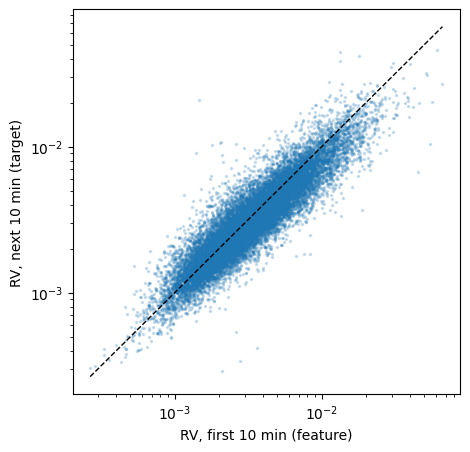

Correlation of log RV: 0.911


In [ ]:
s = df.sample(min(20000, len(df)), random_state=SEED)
fig, ax = plt.subplots(figsize=(5, 5))
ax.scatter(s.rv1, s.target, s=2, alpha=0.2)
lims = [s[["rv1", "target"]].min().min(), s[["rv1", "target"]].max().max()]
ax.plot(lims, lims, "k--", lw=1)
ax.set(xscale="log", yscale="log", xlabel="RV, first 10 min (feature)", ylabel="RV, next 10 min (target)")
plt.show()
print(f"Correlation of log RV: {np.corrcoef(np.log(df.rv1), np.log(df.target))[0,1]:.3f}")

## 3. Train / validation / test split — by time window

The same `time_id` across different stocks shares the same market conditions. If stock A's window 1234 is in training and stock B's window 1234 is in test, the model has effectively seen the test period (via the market-wide features, or simply via correlated stocks). So we split **groups of `time_id`**, not rows:

- **70% train** — fit models
- **10% validation** — early stopping for LightGBM
- **20% test** — touched once, at the end

*Caveat for the write-up:* Optiver shuffled the `time_id`s, so they are not in chronological order. This split prevents same-period leakage, but it is not a true walk-forward (train-on-past, test-on-future) test.

In [ ]:
def group_split(frame, test_size, seed):
    gss = GroupShuffleSplit(n_splits=1, test_size=test_size, random_state=seed)
    a, b = next(gss.split(frame, groups=frame.time_id))
    return frame.iloc[a], frame.iloc[b]

trainval, test = group_split(df, 0.20, SEED)
tr, va = group_split(trainval, 0.125, SEED)   # 0.125 * 0.8 = 10% of total

assert not set(tr.time_id) & set(test.time_id)
assert not set(va.time_id) & set(test.time_id)
assert not set(tr.time_id) & set(va.time_id)
print({k: f"{len(v):,} rows / {v.time_id.nunique()} windows" for k, v in [("train", tr), ("val", va), ("test", test)]})

{'train': '300,251 rows / 2681 windows', 'val': '42,895 rows / 383 windows', 'test': '85,786 rows / 766 windows'}


## 4. Model 1 — naive persistence

Predict next-10-min vol = last-10-min vol. No fitting at all. Every model after this must beat it to justify existing.

A second version scales by a single constant fitted on training data, because vol in the next window isn't exactly the same size on average (it mean-reverts).

In [ ]:
results = {}
results["Naive: target = RV(first 10 min)"] = rmspe(test.target, test.rv1)

# Best single scale factor under RMSPE: minimise sum(((y - k x)/y)^2) -> k = sum(x/y) / sum((x/y)^2)
q = tr.rv1 / tr.target
k = q.sum() / (q ** 2).sum()
results[f"Naive, scaled (x{k:.3f})"] = rmspe(test.target, k * test.rv1)
pd.Series(results, name="test RMSPE")

,test RMSPE
Naive: target = RV(first 10 min),0.3423
"Naive, scaled (x0.837)",0.2821


## 5. Model 2 — linear regression in log space

Volatility is multiplicative and heavy-tailed, so we work in logs: $\log \hat y = \beta_0 + \sum_j \beta_j \log x_j$. This is a log-linear cousin of the HAR model used in the vol literature (recent vol at several horizons + a market term). The coefficients are directly interpretable as elasticities.

One subtlety: fitting in logs and exponentiating gives an estimate of the *median*, which sits below the mean for a skewed variable like vol — and RMSPE wants something different again. A single scale factor, fitted on the training set, fixes this.

In [ ]:
lin_feats = ["rv1", "rv1_last300", "rv1_last150", "mkt_rv1", "spread"]
Xl = lambda d: np.log(d[lin_feats].clip(lower=1e-8))

lin = LinearRegression().fit(Xl(tr), np.log(tr.target))

# exp(prediction in logs) estimates the *median*, not the RMSPE-optimal value.
# Correct with one scale factor fitted on TRAIN (same formula as the scaled naive model).
q = np.exp(lin.predict(Xl(tr))) / tr.target
k_lin = q.sum() / (q ** 2).sum()
results["Linear (log-log), 5 features"] = rmspe(test.target, k_lin * np.exp(lin.predict(Xl(test))))
print(f"retransformation scale factor: {k_lin:.3f}")

display(pd.Series(lin.coef_, index=lin_feats, name="coefficient (elasticity)"))
pd.Series(results, name="test RMSPE")

retransformation scale factor: 0.900


,coefficient (elasticity)
rv1,0.5399
rv1_last300,0.1757
rv1_last150,0.0802
mkt_rv1,0.0104
spread,0.0616


,test RMSPE
Naive: target = RV(first 10 min),0.3423
"Naive, scaled (x0.837)",0.2821
"Linear (log-log), 5 features",0.2582


## 6. Model 3 — LightGBM

Gradient-boosted trees on all features plus `stock_id` as a categorical (lets the model learn per-stock vol levels).

To optimise RMSPE directly, we train with squared error but **weight each row by $1/y^2$**: then the weighted squared error is exactly the squared percentage error.

Hyperparameters are deliberately ordinary — the point is an honest baseline, not leaderboard tuning. Early stopping uses the validation set only.

In [ ]:
features = [c for c in df.columns if c not in ("target", "time_id")]

def to_lgb(d, ref=None):
    X = d[features].copy(); X["stock_id"] = X.stock_id.astype("category")
    return lgb.Dataset(X, d.target, weight=1 / d.target ** 2, reference=ref, categorical_feature=["stock_id"])

def lgb_X(d):
    X = d[features].copy(); X["stock_id"] = X.stock_id.astype("category"); return X

params = dict(objective="rmse", learning_rate=0.05, num_leaves=63, min_data_in_leaf=100,
              feature_fraction=0.8, bagging_fraction=0.8, bagging_freq=1, lambda_l2=1.0,
              seed=SEED, verbose=-1)

dtr = to_lgb(tr); dva = to_lgb(va, ref=dtr)
model = lgb.train(params, dtr, num_boost_round=3000, valid_sets=[dva],
                  callbacks=[lgb.early_stopping(100), lgb.log_evaluation(200)])
pred_lgb = model.predict(lgb_X(test), num_iteration=model.best_iteration)
results["LightGBM, all features"] = rmspe(test.target, pred_lgb)
pd.Series(results, name="test RMSPE")

Training until validation scores don't improve for 100 rounds
[200]	valid_0's l2: 2.12081e-07
[400]	valid_0's l2: 2.11244e-07
Early stopping, best iteration is:
[443]	valid_0's l2: 2.11029e-07


,test RMSPE
Naive: target = RV(first 10 min),0.3423
"Naive, scaled (x0.837)",0.2821
"Linear (log-log), 5 features",0.2582
"LightGBM, all features",0.2235


## 7. What mattered?

Two views:
- **Gain importance** — how much each feature reduced the loss across all tree splits.
- **Ablation** — retrain without a feature group and see how much test RMSPE gets worse. This is the more honest measure: gain importance spreads credit across correlated features (the various RV columns all carry similar information).

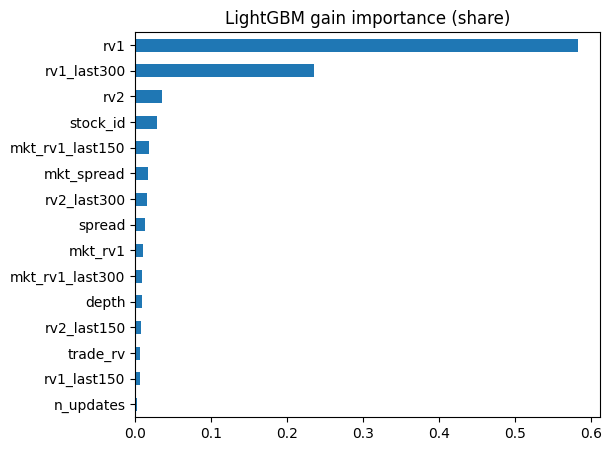

In [ ]:
imp = pd.Series(model.feature_importance("gain"), index=features).sort_values()
imp = imp / imp.sum()
imp.tail(15).plot.barh(figsize=(6, 5), title="LightGBM gain importance (share)"); plt.show()

In [ ]:
groups = {
    "market-wide (mkt_*)": [c for c in features if c.startswith("mkt_")],
    "trades": ["trade_rv", "n_trades", "trade_size", "trade_orders"],
    "spread/depth/imbalance": ["spread", "depth", "imbalance"],
    "stock_id": ["stock_id"],
}

def fit_without(drop):
    keep = [c for c in features if c not in drop]
    def ds(d, ref=None):
        X = d[keep].copy()
        cat = ["stock_id"] if "stock_id" in keep else []
        if cat: X["stock_id"] = X.stock_id.astype("category")
        return lgb.Dataset(X, d.target, weight=1 / d.target ** 2, reference=ref, categorical_feature=cat), X
    dtr_, _ = ds(tr); dva_, _ = ds(va, dtr_); _, Xte = ds(test)
    m = lgb.train(params, dtr_, 3000, valid_sets=[dva_], callbacks=[lgb.early_stopping(100, verbose=False)])
    return rmspe(test.target, m.predict(Xte, num_iteration=m.best_iteration))

base = results["LightGBM, all features"]
abl = pd.DataFrame({g: {"test RMSPE without": (r := fit_without(cols)), "change vs full model": r - base}
                    for g, cols in groups.items()}).T
abl.sort_values("change vs full model", ascending=False)

,test RMSPE without,change vs full model
market-wide (mkt_*),0.2288,0.0054
stock_id,0.2274,0.0039
spread/depth/imbalance,0.2233,-0.0001
trades,0.2228,-0.0006


## 8. Where does it fail?

RMSPE punishes over-prediction on very calm windows hardest (small $y$ in the denominator). Look at errors by how volatile the window turned out to be.

In [ ]:
ev = test[["stock_id", "time_id", "target", "rv1"]].copy()
ev["pred"] = pred_lgb
ev["pct_err"] = (ev.pred - ev.target) / ev.target
ev["target_decile"] = pd.qcut(ev.target, 10, labels=False) + 1

by_dec = ev.groupby("target_decile").agg(
    rmspe=("pct_err", lambda e: np.sqrt(np.mean(e ** 2))),
    mean_signed_pct_err=("pct_err", "mean"))
display(by_dec)

worst = ev.groupby("stock_id").pct_err.apply(lambda e: np.sqrt(np.mean(e ** 2))).sort_values(ascending=False)
print("Hardest stocks (test RMSPE):"); display(worst.head(5))

,rmspe,mean_signed_pct_err
target_decile,,
1,0.3137,0.1315
2,0.2087,0.0459
3,0.1967,0.0133
4,0.1959,-0.0072
5,0.2001,-0.0267
6,0.2010,-0.0460
7,0.2074,-0.0592
8,0.2124,-0.0753
9,0.2224,-0.0936


Hardest stocks (test RMSPE):


,pct_err
stock_id,
31,0.5869
37,0.3039
88,0.2931
18,0.2879
27,0.2810


## 9. Results summary

In [ ]:
summary = pd.Series(results, name="test RMSPE").to_frame()
naive = results["Naive: target = RV(first 10 min)"]
summary["improvement vs naive"] = (1 - summary["test RMSPE"] / naive).map("{:.1%}".format)
summary

,test RMSPE,improvement vs naive
Naive: target = RV(first 10 min),0.3423,0.0%
"Naive, scaled (x0.837)",0.2821,17.6%
"Linear (log-log), 5 features",0.2582,24.6%
"LightGBM, all features",0.2235,34.7%


## 10. Write-up

**Task.** Predict each stock's realised volatility over the next 10 minutes from the previous 10 minutes of order-book and trade data. The data is Optiver's Realized Volatility Prediction set on Kaggle: 112 stocks, 3,830 ten-minute windows, 428,932 rows. The metric is RMSPE (root mean squared percentage error), so a miss on a calm stock counts as much as a miss on a volatile one.

**Setup.** I built one row per (stock, window) with 19 hand-made features, which took 79 seconds for all 112 stocks:
- realised volatility of the weighted average price (WAP) over the full window, the last 300 seconds and the last 150 seconds
- relative bid-ask spread, book depth and size imbalance
- trade activity
- the average of each feature across all stocks in the same window ("market-wide")

I split the windows 70/10/20 into train, validation and test **by `time_id`**, so no window appears in more than one set. Splitting by row would let the same market period leak from training into test. I used the test set once, at the end.

**Results.**

| Model | Test RMSPE | vs naive |
|---|---|---|
| Naive persistence (next vol = last vol) | 0.3423 | — |
| Naive, scaled by one fitted constant (×0.837) | 0.2821 | −17.6% |
| Linear regression in logs, 5 features | 0.2582 | −24.6% |
| LightGBM, all features, weighted by 1/y² | **0.2235** | **−34.7%** |

**What worked and why.**

- **Volatility clustering is most of the signal.** Log volatility in the first and next 10 minutes has a correlation of 0.911. In LightGBM, the full-window and last-5-minute volatility features account for about 80% of the total gain importance.
- **Volatility mean-reverts.** The best constant scaling of the naive forecast is 0.837, so the next window is on average about 16% calmer than the last. In the log-linear model, the elasticities on the stock's own volatility sum to about 0.80. A window 10% more volatile than usual predicts a next window only about 8% above usual. The scatter plot shows the same thing: the most volatile windows sit below the diagonal.
- **Recent activity counts for more.** The last-5-minute and last-2.5-minute volatility features get positive weight on top of full-window volatility. The second half of the window is therefore weighted more heavily than the first.
- **Market-wide features were the most valuable addition beyond the stock's own volatility.** Removing them worsens test RMSPE by 0.0054 (0.2235 → 0.2288). In the linear model the market-volatility coefficient is close to zero (0.01). So the trees use the market regime in a non-linear way, plausibly as how a stock's volatility compares with the market that window, rather than as an extra additive term.
- **`stock_id` helps (+0.0039)**, letting the model learn per-stock volatility levels.
- **Spread, depth, imbalance and trade features added nothing measurable.** Removing them changes RMSPE by less than 0.001, within noise. Quote-based realised volatility already appears to capture what trades tell us over a 10-minute window.
- **Aligning the loss with the metric.** Training with sample weights of 1/y² makes the weighted squared error equal to the squared percentage error, so LightGBM optimises RMSPE directly. For the linear model, exponentiating a log-space prediction targets the median rather than the RMSPE-optimal value, so a single scale factor of 0.900 fitted on train corrects it.

**Where it fails.**

- **The model shrinks towards typical volatility.** In the calmest 10% of windows it over-predicts by 13% on average, and in the most volatile 10% it under-predicts by 13%.
- **The calmest decile has the worst error (RMSPE 0.31 against about 0.20 mid-range).** Small targets in the denominator magnify any miss, so that decile dominates the metric.
- **One stock is a clear outlier.** Stock 31 has a test RMSPE of 0.59, about double the next-worst stock (0.30).

**Limitations.**

- Optiver shuffled the `time_id`s, so this is not a walk-forward test (train on the past, test on the future). Performance on genuinely future data would likely be worse.
- Results come from a single split with no confidence intervals. Ablation differences below about 0.001 should be treated as noise.
- There was no hyperparameter search beyond early stopping. Scores aren't directly comparable to the competition leaderboard, which used a different test set.

**Next steps.**
- Repeat over several grouped splits to put error bars on the ablation.
- Add features from groups of similar stocks (clustered by return correlation).
- Model the calmest windows separately.
- Investigate stock 31.